In [2]:
import os
from Bio import Seq,SeqIO
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from Bio import AlignIO
import matplotlib as mpl
%matplotlib inline
%config InlineBackend.figure_format = 'svg'
plt.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['figure.dpi']= 500

## Make MSA

In [3]:
ISDra2_seq = '''MIRNKAFVVRLYPNAAQTELINRTLGSARFVYNHFLARRIAAYKESGKGLTYGQTSSELT
LLKQAEETSWLSEVDKFALQNSLKNLETAYKNFFRTVKQSGKKVGFPRFRKKRTGESYRT
QFTNNNIQIGEGRLKLPKLGWVKTKGQQDIQGKILNVTVRRIHEGHYEASVLCEVEIPYL
PAAPKFAAGVDVGIKDFAIVTDGVRFKHEQNPKYYRSTLKRLRKAQQTLSRRKKGSARYG
KAKTKLARIHKRIVNKRQDFLHKLTTSLVREYEIIGTEHLKPDNMRKNRRLALSISDAGW
GEFIRQLEYKAAWYGRLVSKVSPYFPSSQLCHDCGFKNPEVKNLAVRTWTCPNCGETHDR
DENAALNIRREALVAAGISDTLNAHGGYVRPASAGNGLRSENHATLVV'''.replace('\n', '')

In [4]:
len(ISDra2_seq)

408

In [5]:
ISDra2 = [SeqIO.SeqRecord(Seq.Seq(ISDra2_seq), id='ISDra2', name='', description='')]

In [6]:
Xiang_TnpBs = pd.read_csv('../data/TnpBs_Xiang_2023.csv', sep='\t')

In [7]:
Xiang_TnpBs = Xiang_TnpBs.assign(WT_Sequence = Xiang_TnpBs['Sequence'].apply(lambda x: x.replace(
    'MGSPKKKRKVEF', '').replace('GSKRPAATKKAGQAKKKKTGYPYDVPDYAYPYDVPDYAYPYDVPDYA', '')))

In [8]:
Xiang_Seq = [SeqIO.SeqRecord(Seq.Seq(Xiang_TnpBs.loc[i, 'WT_Sequence']), id=Xiang_TnpBs.loc[i, 'Name'], name='',
                            description='') for i in Xiang_TnpBs.index]

In [9]:
SeqIO.write(ISDra2+Xiang_Seq, 'reference_TnpB.faa', 'fasta')

79

In [10]:
!cat reference_TnpB.faa ../data/ISPmu1.faa > to_align.faa

In [11]:
!muscle5.1 -align to_align.faa -output aligned.faa


muscle 5.1.linux64 [12f0e2]  1584Gb RAM, 192 cores
Built Jan 13 2022 23:17:13
(C) Copyright 2004-2021 Robert C. Edgar.
https://drive5.com

Input: 80 seqs, avg length 405, max 528

00:00 4.4Mb  CPU has 192 cores, defaulting to 20 threads
00:06 1.4Gb   100.0% Calc posteriors
00:08 1.4Gb   100.0% Consistency (1/2)
00:10 1.4Gb   100.0% Consistency (2/2)
00:10 1.4Gb   100.0% UPGMA5           
00:12 1.5Gb   100.0% Refining


## Process MSA

In [12]:
# defined wrt Dra2 sequence
domains = {'WED-1':(0,12), 'REC':(13,115), 'WED-2':(116,176), 'L':(177,184), 'RuvC-1':(185,326), 'TNB':(327,359), 'RuvC-2':(360,408)}

In [13]:
# read alignment
aln = {s.id:s for rec in AlignIO.parse('aligned.faa', 'fasta') for s in rec}

In [14]:
# find aln coordinates 
domains_aln = {}
i, j = 0, 0
for d in domains:
    start = domains[d][0]
    end = domains[d][1]
    aln_stat = j
    while i < end:
        if aln['ISDra2'][j]!='-':
            i += 1
        j+= 1
    aln_end = j
    domains_aln[d] = (aln_stat, aln_end)

In [15]:
domains_aln['RuvC-2'] = (domains_aln['RuvC-2'][0], len(aln['ISDra2'].seq))

In [16]:
domains_aln = pd.Series(domains_aln)
domains_aln

WED-1         (0, 82)
REC         (82, 338)
WED-2      (338, 505)
L          (505, 568)
RuvC-1     (568, 853)
TNB        (853, 920)
RuvC-2    (920, 1170)
dtype: object

In [17]:
domain_len = {}
for ID in aln:
    domain_len[ID] = []
    for d in domains_aln.index:
        ds, de = domains_aln.loc[d]
        L = sum([aa!='-' for aa in aln[ID].seq[ds:de]])
        domain_len[ID].append(L)

In [18]:
domain_end = {Cas:np.cumsum(domain_len[Cas]) for Cas in domain_len}

In [19]:
domain_start = {Cas:[domain_end[Cas][i-1]+1 if i>0 else 1 for i in range(
    len(domain_end[Cas]))] for Cas in domain_end}

In [20]:
domain_coords = {}
for Cas in domain_start:
    domain_coords[Cas] = {}
    for i,dom in enumerate(domains_aln.index):
        domain_coords[Cas][dom] = '{}-{}'.format(domain_start[Cas][i], domain_end[Cas][i])

In [22]:
domain_coords = pd.DataFrame(domain_coords).transpose()

In [24]:
domain_coords.loc[['ISDra2', 'ISPmu1', 'ISAam1', 'ISYmu1', 'ISDge10']]

,WED-1,REC,WED-2,L,RuvC-1,TNB,RuvC-2
ISDra2,1-12,13-115,116-176,177-184,185-326,327-359,360-408
ISPmu1,1-12,13-108,109-167,168-174,175-327,328-359,360-378
ISAam1,1-11,12-108,109-171,172-179,180-318,319-349,350-369
ISYmu1,1-12,13-110,111-171,172-178,179-327,328-359,360-382
ISDge10,1-13,14-111,112-169,170-180,181-318,319-349,350-391


In [25]:
domain_starts = domain_coords.apply(lambda x: [int(y.split('-')[0]) for y in x])-1
domain_ends = domain_coords.apply(lambda x: [int(y.split('-')[1]) for y in x])

In [26]:
domain_length = domain_ends-domain_starts

In [27]:
domain_length = domain_length.assign(Total=domain_length.sum(axis=1))

In [28]:
domain_length.loc['ISPmu1']

WED-1      12
REC        96
WED-2      59
L           7
RuvC-1    153
TNB        32
RuvC-2     19
Total     378
Name: ISPmu1, dtype: int64

## Make color annotation

In [29]:
color_anno = '''55  90 0 0 174  224  232 # RuvC-1
91 246 0 0 247 247 247 # REC
247 454 0 0 202 202 202 # L
55  90 0 0 174  224  232 # RuvC-2
510 540 0 0 250 239 0 # WED-1
247 454 0 0 202 202 202 # CTD
655 666 0 0 250 239 0 # WED-2
667 841 0 0 170 165 234 # TNB'''.split('\n')
color_anno = [[t for t in l.split(' ') if len(t)>0][2:] for l in color_anno]

In [30]:
color_anno = {l[-1]:l[2:5] for l in color_anno}

In [31]:
domain_colors = {dom:'#%02x%02x%02x' % tuple([int(c) for c in color_anno[dom]]) for dom in color_anno}

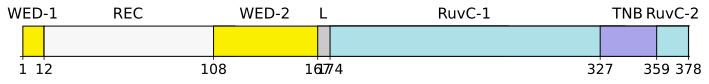

In [33]:
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 0.7))

Cas9 = 'ISPmu1'
height = 0.8
ends = []
patches = []
for i,dom in enumerate(domain_coords.columns):
    start,end = domain_coords.loc[Cas9,dom].split('-')
    start, end = int(start), int(end)
    ends.append(end)
    ax.text(start + (end-start)/2, 1, dom, size=15, ha='center', rotation=0)
    ax.add_patch(mpatches.Rectangle((start, 0), end, height, facecolor=domain_colors[dom], alpha=1, edgecolor='k'))
ax.add_patch(mpatches.Rectangle((end, 0), end+50, height, facecolor='white', alpha=1, edgecolor='k'))
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.set_yticks([])
ax.set_xticks([1] + [e+1 for e in ends][0:-1] + ends[-1:])
ax.set_xticklabels([1] + ends)
ax.set_xlim(-0.5,end+0.5)
for x in ax.get_xticklabels():
    x.set_rotation(0)
    x.set_ha('center')
    x.set_size(14)
    
plt.show()